In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta.

In [3]:
pregunta_1 = "1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  "
pregunta_2 = "2. Calcule la varianza y la desviación típica de la duración del proyecto.  "
pregunta_3 = "3. ¿Qué probabilidad hay de terminar el proyecto en 33 semanas o menos?  "
pregunta_4 = "4. ¿Qué probabilidad hay de terminar entre las semanas 30 y 33?  "
pregunta_5 = "5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 95% de cumplirla?  "
pregunta_6 = "6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 95% de probabilidad sin modificar el proyecto?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

2. Calcule la varianza y la desviación típica de la duración del proyecto.  

3. ¿Qué probabilidad hay de terminar el proyecto en 33 semanas o menos?  

4. ¿Qué probabilidad hay de terminar entre las semanas 30 y 33?  

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 95% de cumplirla?  

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 95% de probabilidad sin modificar el proyecto?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 7       , 0.8               ),
    ('B'     , '---'      , 8       , 0.5               ),
    ('C'     , 'A,B'      , 8       , 0.8               ),
    ('D'     , 'C'        , 3       , 0.5               ),
    ('E'     , 'C'        , 3       , 0.5               ),
    ('F'     , 'D'        , 5       , 0.4               ),
    ('G'     , 'E,F'      , 4       , 0.3               ),
    ('H'     , 'E,F'      , 1       , 0.1               ),
    ('I'     , 'G,H'      , 3       , 0.1               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,7,0.8
B,---,8,0.5
C,"A,B",8,0.8
D,C,3,0.5
E,C,3,0.5
F,D,5,0.4
G,"E,F",4,0.3
H,"E,F",1,0.1
I,"G,H",3,0.1


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Determine la duración media del proyecto y su(s) camino(s) crítico(s).  

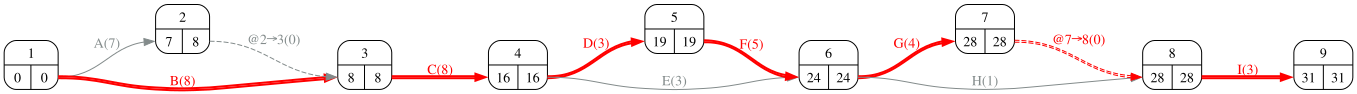

In [7]:
#| fig-cap: "Grafo PERT con tiempos de los nodos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [8]:
#| tbl-cap: "Holgura total de las actividades"
#| label: tbl-holguras
resultados_pert = proyecto.calculate_pert(durations=datos_proyecto['duration'])
resultados_pert['activities'].T

,@2→3,@7→8,A,B,C,D,E,F,G,H,I
H_total,1,0,1,0,0,0,5,0,0,3,0


In [9]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
Markdown(f'La duración media del proyecto es {duracion_media} semanas y tiene {len(rutas_criticas)} ruta(s) crítica(s).')

Route_5: B - C - D - F - G - I


La duración media del proyecto es 31 semanas y tiene 1 ruta(s) crítica(s).

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Calcule la varianza y la desviación típica de la duración del proyecto.  

Por el teorema central del límite, la duración de una ruta es aproximadamente normal con media la suma de las medias y varianza la suma de las varianzas de sus actividades. Para el proyecto se toma la ruta crítica; si hay varias, la de mayor varianza, que es la hipótesis más prudente (la verdadera distribución del máximo de varias rutas no es normal, y el método PERT la aproxima así).

In [11]:
#| tbl-cap: "Varianza de las rutas críticas"
#| label: tbl-varianzaRutas
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(durations=datos_proyecto['duration'],
                                                                   variances=datos_proyecto['variance'])
varianza_rutas

,Activities,Variance
Route_5,"B, C, D, F, G, I",1.40


In [12]:
Markdown(f'La varianza del proyecto es {desviacion_proyecto**2:.3f} y su desviación típica {desviacion_proyecto:.3f} semanas.')

La varianza del proyecto es 1.400 y su desviación típica 1.183 semanas.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. ¿Qué probabilidad hay de terminar el proyecto en 33 semanas o menos?  

Con $T \sim N(\mu, \sigma)$: $P(T \le t) = \Phi\left(\frac{t - \mu}{\sigma}\right)$.

In [14]:
plazo = 33
z = (plazo - duracion_media) / desviacion_proyecto
probabilidad_plazo = norm.cdf(z)
Markdown(f'z = ({plazo} − {duracion_media}) / {desviacion_proyecto:.3f} = {z:.3f}, luego P(T ≤ {plazo}) = Φ({z:.3f}) = {probabilidad_plazo:.4f} ({probabilidad_plazo*100:.1f} %).')

z = (33 − 31) / 1.183 = 1.690, luego P(T ≤ 33) = Φ(1.690) = 0.9545 (95.5 %).

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. ¿Qué probabilidad hay de terminar entre las semanas 30 y 33?  

In [16]:
t_a, t_b = 30, 33
p_b = norm.cdf((t_b - duracion_media) / desviacion_proyecto)
p_a = norm.cdf((t_a - duracion_media) / desviacion_proyecto)
Markdown(f'P({t_a} < T ≤ {t_b}) = Φ({(t_b - duracion_media) / desviacion_proyecto:.3f}) − Φ({(t_a - duracion_media) / desviacion_proyecto:.3f}) '
         f'= {p_b:.4f} − {p_a:.4f} = {p_b - p_a:.4f} ({(p_b - p_a)*100:.1f} %).')

P(30 < T ≤ 33) = Φ(1.690) − Φ(-0.845) = 0.9545 − 0.1990 = 0.7555 (75.6 %).

## Apartado 5

In [17]:
display(Markdown(pregunta_5))

5. ¿Qué duración puede comprometerse con el cliente con una probabilidad del 95% de cumplirla?  

Se busca $t$ tal que $P(T \le t) = p$, es decir, $t = \mu + z_p\,\sigma$ con $z_p = \Phi^{-1}(p)$.

In [18]:
probabilidad_objetivo = 0.95
z_p = norm.ppf(probabilidad_objetivo)
duracion_comprometida = duracion_media + z_p * desviacion_proyecto
Markdown(f'z = {z_p:.3f}; t = {duracion_media} + {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_comprometida:.2f} semanas. '
         f'Como el calendario se mide en semanas enteras, se comprometerían {int(np.ceil(duracion_comprometida))} semanas.')

z = 1.645; t = 31 + 1.645 × 1.183 = 32.95 semanas. Como el calendario se mide en semanas enteras, se comprometerían 33 semanas.

## Apartado 6

In [19]:
display(Markdown(pregunta_6))

6. ¿Qué probabilidad hay de terminar en la duración media o antes? ¿Puede garantizarse esa duración con un 95% de probabilidad sin modificar el proyecto?  

In [20]:
Markdown(f'''La duración media es la mediana de la normal, así que P(T ≤ {duracion_media}) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 95% haría falta que la media del proyecto fuera {duracion_media} − {z_p:.3f} × {desviacion_proyecto:.3f} = {duracion_media - z_p * desviacion_proyecto:.2f} semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.''')

La duración media es la mediana de la normal, así que P(T ≤ 31) = 0.5: sólo la mitad de las veces se terminaría en la duración media o antes. Para garantizarla con un 95% haría falta que la media del proyecto fuera 31 − 1.645 × 1.183 = 29.05 semanas, es decir, reducir el proyecto (acortando actividades críticas) o reducir su varianza. Sin tocar el proyecto no es posible.